In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:

df = pd.read_csv('deliriumwatch_master.csv')
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)

Shape: (57992, 31)

Columns: ['subject_id', 'stay_id', 'delirium_label', 'age', 'gender', 'first_careunit', 'icu_los_hours', 'avg_sofa', 'max_sofa', 'admission_sofa', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'rr_mean', 'rr_std', 'spo2_mean', 'spo2_min', 'nibp_mean', 'nibp_min', 'abp_mean', 'propofol_total', 'midazolam_total', 'lorazepam_total', 'dexmedetomidine_total', 'fentanyl_total', 'unique_sedation_drugs', 'nid_score', 'night_day_ratio', 'night_interventions', 'day_interventions']

Data types:
 subject_id                 int64
stay_id                    int64
delirium_label             int64
age                        int64
gender                       str
first_careunit               str
icu_los_hours              int64
avg_sofa                 float64
max_sofa                   int64
admission_sofa             int64
hr_mean                  float64
hr_std                   float64
hr_min                   float64
hr_max                   float64
rr_mean                  float64


In [4]:

cols = [
    'subject_id',     
    'stay_id',           
    'icu_los_hours',  
    'night_interventions',
    'day_interventions'     
]

df_clean = df.drop(columns=cols)
print("Shape", df_clean.shape)
print("Remaining columns:", df_clean.columns.tolist())

Shape (57992, 26)
Remaining columns: ['delirium_label', 'age', 'gender', 'first_careunit', 'avg_sofa', 'max_sofa', 'admission_sofa', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'rr_mean', 'rr_std', 'spo2_mean', 'spo2_min', 'nibp_mean', 'nibp_min', 'abp_mean', 'propofol_total', 'midazolam_total', 'lorazepam_total', 'dexmedetomidine_total', 'fentanyl_total', 'unique_sedation_drugs', 'nid_score', 'night_day_ratio']


In [5]:
# Missing value analysis
missing = df_clean.isnull().sum()
missing_pct = (missing / len(df_clean) * 100)

missing_df = pd.DataFrame({
    'missing_count': missing,
    'missing_pct': missing_pct
}).sort_values('missing_pct', ascending=False)

#shows columns that are missing
print(missing_df[missing_df['missing_count'] > 0])

           missing_count  missing_pct
abp_mean           33515    57.792454
nibp_mean            379     0.653538
nibp_min             379     0.653538
rr_std                45     0.077597
rr_mean               38     0.065526
spo2_mean              8     0.013795
spo2_min               8     0.013795
hr_std                 1     0.001724


In [6]:
# creates a flag BEFORE filling
df_clean['abp_measured'] = (
    df_clean['abp_mean'].notnull().astype(int)
)

# Fill abp_mean with 0 (no arterial line = 0 reading)
df_clean['abp_mean'] = df_clean['abp_mean'].fillna(0)

# missing values: filled with median
median_cols = [
    'nibp_mean', 'nibp_min', 
    'rr_std', 'rr_mean',
    'spo2_mean', 'spo2_min', 
    'hr_std'
]
for col in median_cols:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)
    print(f"{col}: filled with median {median_val:.2f}")
print("\nMissing after treatment:", 
      df_clean.isnull().sum().sum())

nibp_mean: filled with median 78.84
nibp_min: filled with median 58.00
rr_std: filled with median 4.09
rr_mean: filled with median 18.93
spo2_mean: filled with median 96.68
spo2_min: filled with median 90.00
hr_std: filled with median 9.48

Missing after treatment: 0


Class distribution:
No delirium (0): 36971 (63.8%)
Delirium    (1): 21021 (36.2%)
Ratio: 1:1.8


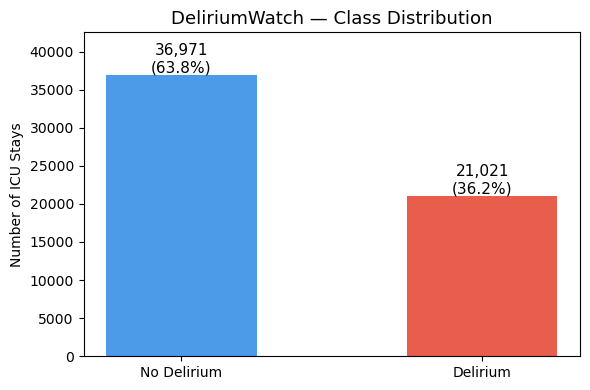

In [7]:
counts = df_clean['delirium_label'].value_counts()
pcts = df_clean['delirium_label'].value_counts(
    normalize=True
) * 100

print("Class distribution:")
print(f"No delirium (0): {counts[0]} ({pcts[0]:.1f}%)")
print(f"Delirium    (1): {counts[1]} ({pcts[1]:.1f}%)")
print(f"Ratio: 1:{counts[0]/counts[1]:.1f}")


fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['No Delirium', 'Delirium'], 
               counts.values,
               color=['#4C9BE8', '#E85D4C'],
               width=0.5)

# Adds count
for bar, count, pct in zip(
    bars, counts.values, pcts.values
):
    ax.text(bar.get_x() + bar.get_width()/2, 
            bar.get_height() + 300,
            f'{count:,}\n({pct:.1f}%)',
            ha='center', fontsize=11)

ax.set_title('DeliriumWatch — Class Distribution', 
             fontsize=13)
ax.set_ylabel('Number of ICU Stays')
ax.set_ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()

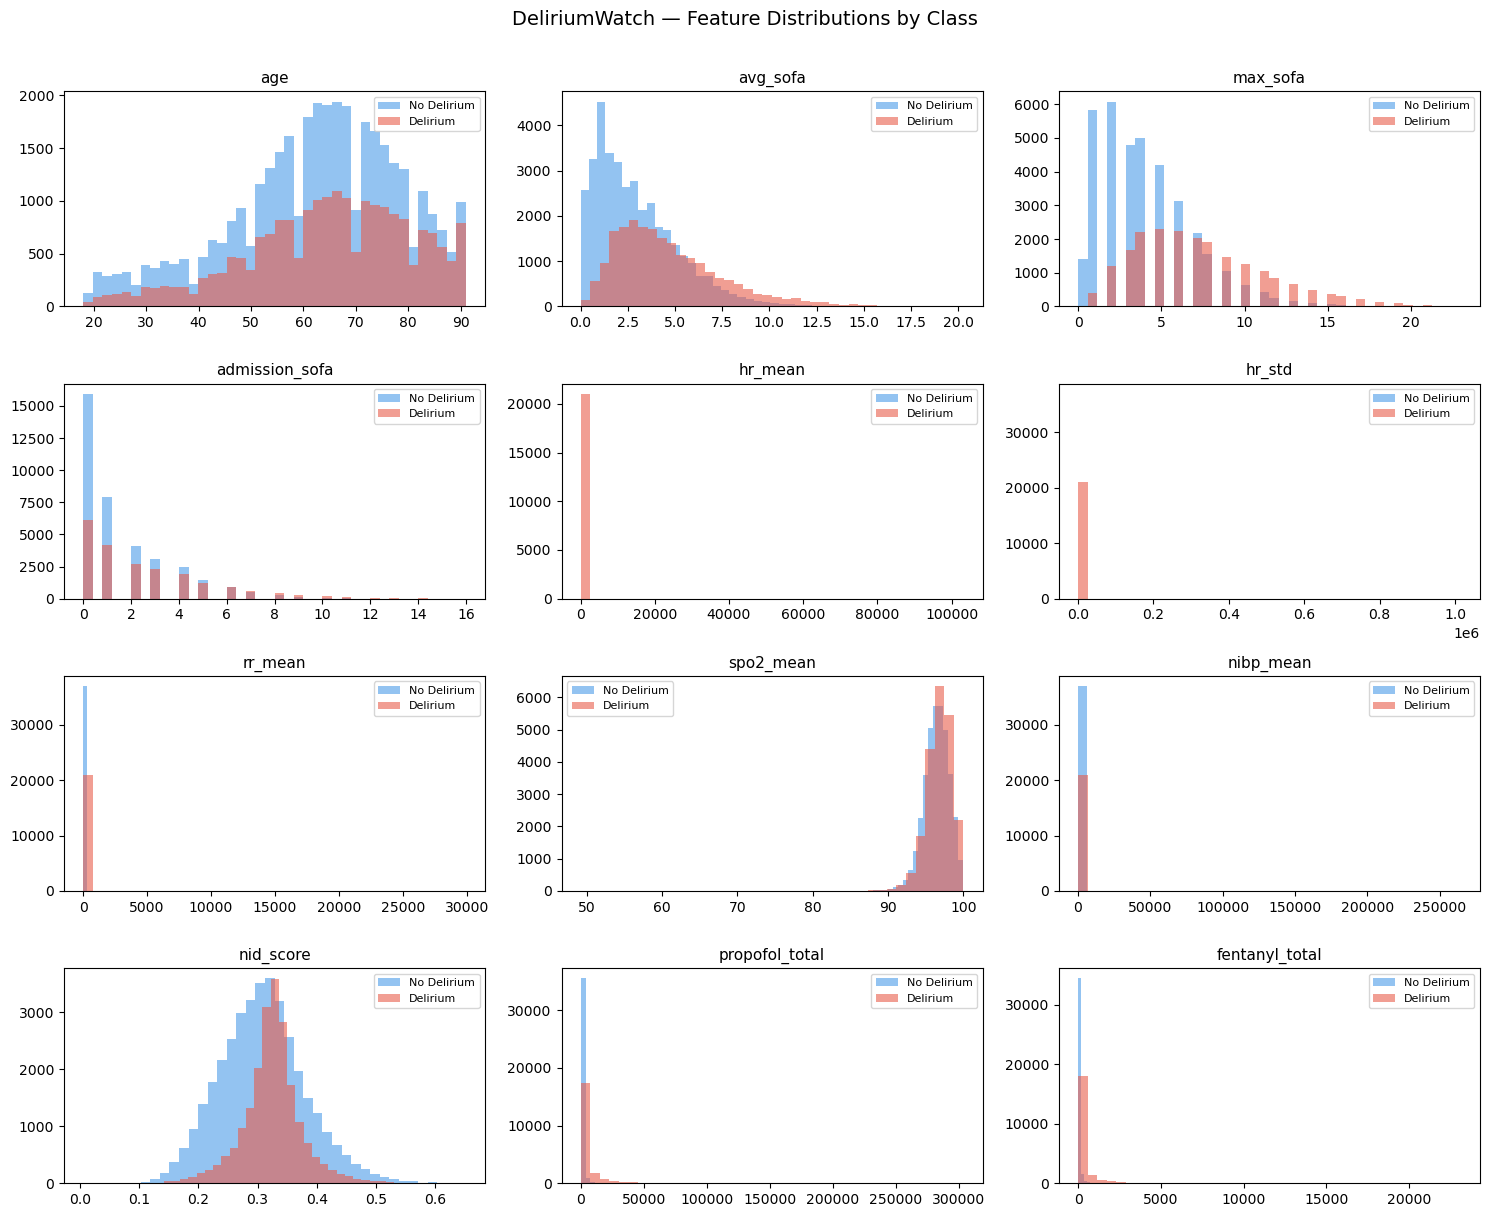

In [8]:
numerical_cols = [
    'age', 'avg_sofa', 'max_sofa', 
    'admission_sofa', 'hr_mean', 'hr_std',
    'rr_mean', 'spo2_mean', 'nibp_mean', 
    'nid_score', 'propofol_total', 
    'fentanyl_total'
]

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    axes[i].hist(
        df_clean[df_clean['delirium_label']==0][col], 
        bins=40, alpha=0.6, 
        color='#4C9BE8', label='No Delirium'
    )
    axes[i].hist(
        df_clean[df_clean['delirium_label']==1][col], 
        bins=40, alpha=0.6, 
        color='#E85D4C', label='Delirium'
    )
    axes[i].set_title(col, fontsize=11)
    axes[i].legend(fontsize=8)

plt.suptitle(
    'DeliriumWatch — Feature Distributions by Class', 
    fontsize=14, y=1.01
)
plt.tight_layout()
plt.show()

In [9]:
# outlier scale
outlier_cols = [
    'hr_mean', 'hr_std', 'hr_min', 'hr_max',
    'rr_mean', 'rr_std', 'spo2_mean', 'spo2_min',
    'nibp_mean', 'nibp_min', 'propofol_total',
    'fentanyl_total'
]

print(f"{'Column':<25} {'Min':>10} {'Max':>15} {'Mean':>10} {'Median':>10}")
print("-" * 75)
for col in outlier_cols:
    print(f"{col:<25} "
          f"{df_clean[col].min():>10.1f} "
          f"{df_clean[col].max():>15.1f} "
          f"{df_clean[col].mean():>10.1f} "
          f"{df_clean[col].median():>10.1f}")

Column                           Min             Max       Mean     Median
---------------------------------------------------------------------------
hr_mean                         26.4        103185.2       86.4       83.4
hr_std                           0.0       1015336.7       33.4        9.5
hr_min                           1.0           132.0       64.4       63.0
hr_max                          36.0      10000000.0      390.1      110.0
rr_mean                          8.8         29936.3       20.1       18.9
rr_std                           0.0        457629.2       14.1        4.1
spo2_mean                       49.2           100.0       96.5       96.7
spo2_min                         0.0           100.0       87.6       90.0
nibp_mean                       30.9        264771.5       90.4       78.8
nibp_min                         1.0           133.0       58.2       58.0
propofol_total                   0.0        303737.4     2195.7        0.0
fentanyl_total          

In [10]:
# These are hard medical limits
clinical_bounds = {
    'hr_mean':  (20, 300),      # HR: 20-300 bpm
    'hr_std':   (0, 50),        # std can't be huge
    'hr_min':   (20, 300),
    'hr_max':   (20, 300),
    'rr_mean':  (4, 60),        # RR: 4-60 breaths/min
    'rr_std':   (0, 15),
    'spo2_mean':(50, 100),      # SpO2: 50-100%
    'spo2_min': (50, 100),
    'nibp_mean':(20, 200),      # BP mean: 20-200 mmHg
    'nibp_min': (20, 200),
    'propofol_total': (0, 50000),  # reasonable ICU dose
    'fentanyl_total': (0, 10000)
}

for col, (lower, upper) in clinical_bounds.items():
    before = df_clean[col].max()
    df_clean[col] = df_clean[col].clip(
        lower=lower, upper=upper
    )
    after = df_clean[col].max()
    if before != after:
        print(f"{col}: clipped max {before:.1f} → {after:.1f}")

print("\nDone. Checking distributions again...")
print(df_clean[list(clinical_bounds.keys())].describe().round(2))

hr_mean: clipped max 103185.2 → 300.0
hr_std: clipped max 1015336.7 → 50.0
hr_max: clipped max 10000000.0 → 300.0
rr_mean: clipped max 29936.3 → 60.0
rr_std: clipped max 457629.2 → 15.0
nibp_mean: clipped max 264771.5 → 200.0
propofol_total: clipped max 303737.4 → 50000.0
fentanyl_total: clipped max 23132.2 → 10000.0

Done. Checking distributions again...
        hr_mean    hr_std    hr_min    hr_max   rr_mean    rr_std  spo2_mean  \
count  57992.00  57992.00  57992.00  57992.00  57992.00  57992.00   57992.00   
mean      84.37     10.39     64.40    112.58     19.37      4.31      96.55   
std       14.28      4.75     13.91     23.74      3.45      1.40       1.77   
min       26.45      0.00     20.00     36.00      8.76      0.00      50.00   
25%       74.37      7.10     55.00     95.00     16.93      3.37      95.53   
50%       83.37      9.48     63.00    110.00     18.93      4.09      96.68   
75%       93.47     12.66     73.00    126.00     21.38      5.00      97.76   
ma

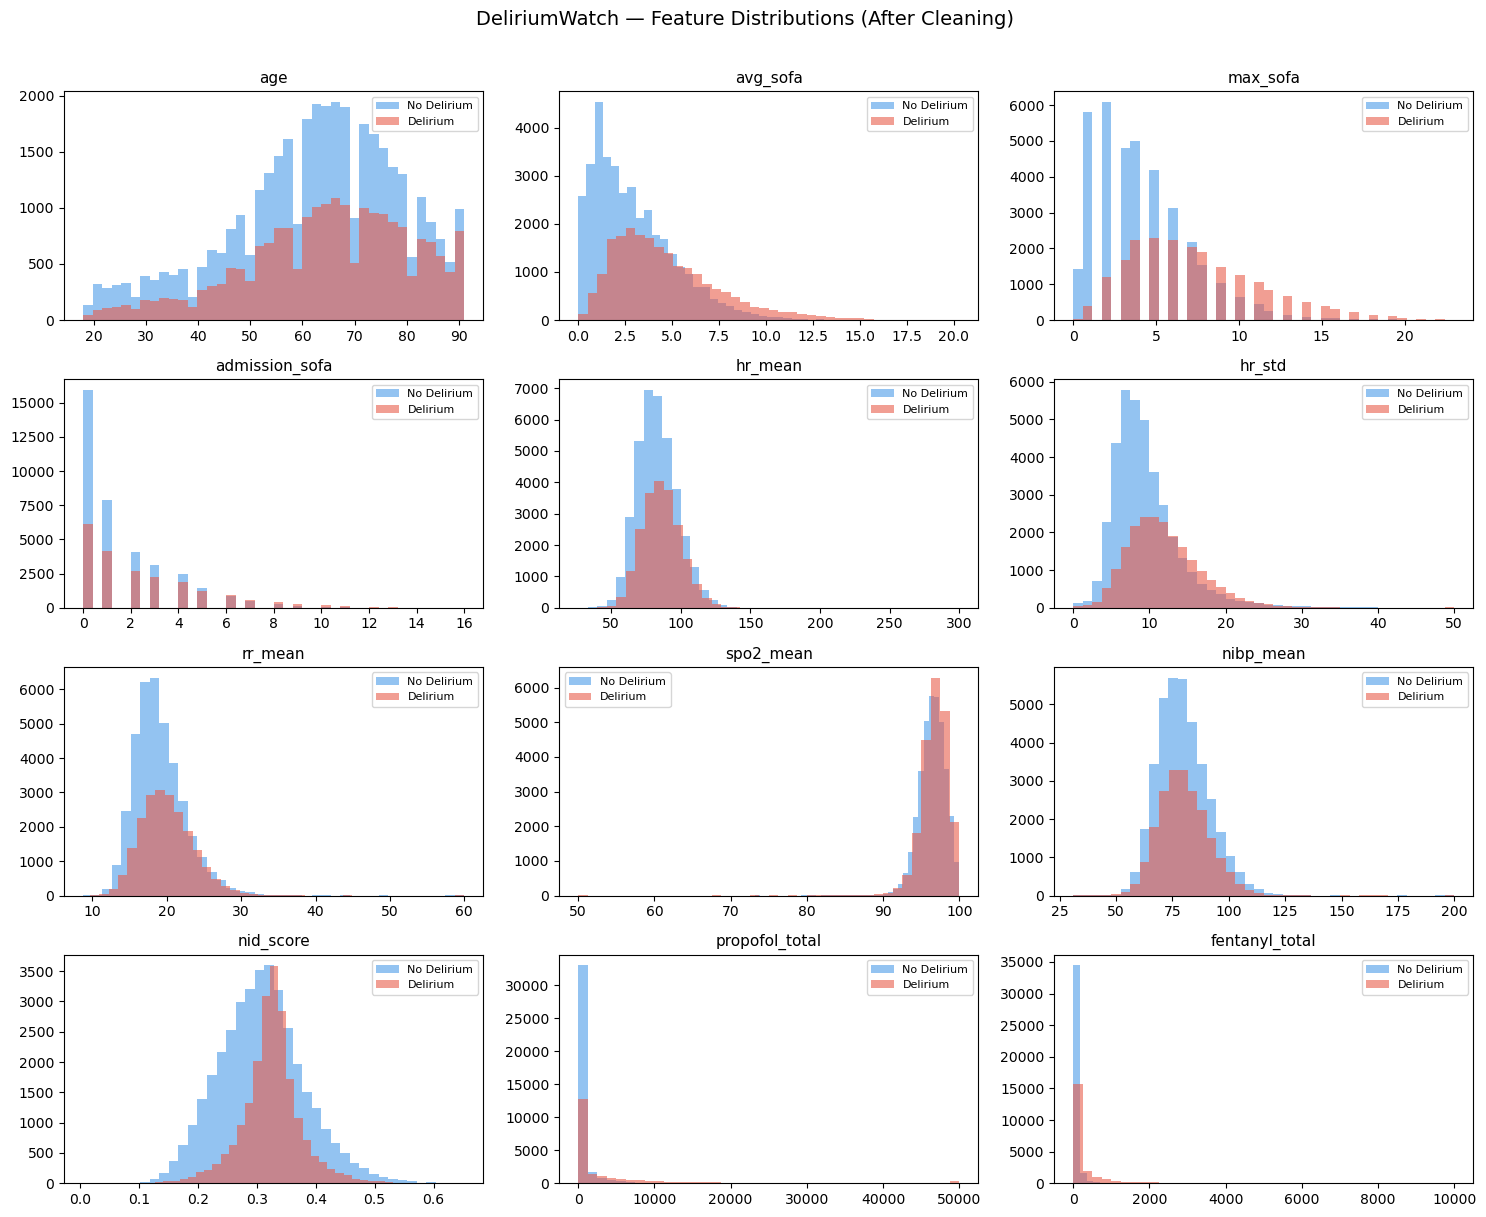

In [11]:
# Re-run distributions with clean data
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    axes[i].hist(
        df_clean[df_clean['delirium_label']==0][col],
        bins=40, alpha=0.6,
        color='#4C9BE8', label='No Delirium'
    )
    axes[i].hist(
        df_clean[df_clean['delirium_label']==1][col],
        bins=40, alpha=0.6,
        color='#E85D4C', label='Delirium'
    )
    axes[i].set_title(col, fontsize=11)
    axes[i].legend(fontsize=8)

plt.suptitle(
    'DeliriumWatch — Feature Distributions (After Cleaning)',
    fontsize=14, y=1.01
)
plt.tight_layout()
plt.show()

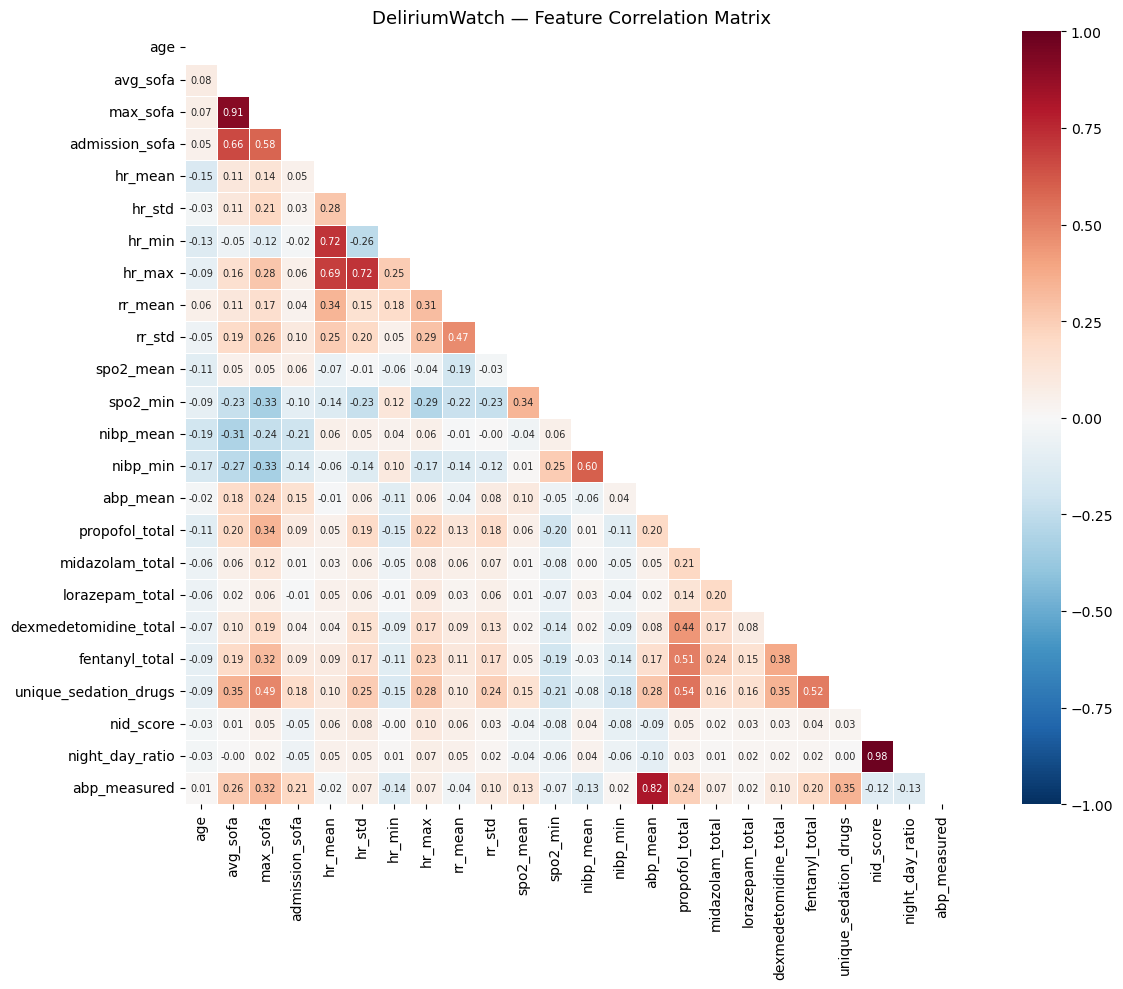

In [12]:
# Correlation heatmap
feature_cols = [col for col in df_clean.columns 
                if col not in ['delirium_label', 
                               'gender', 
                               'first_careunit']]

corr_matrix = df_clean[feature_cols].corr().round(2)

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={'size': 7}
)

plt.title('DeliriumWatch — Feature Correlation Matrix', 
          fontsize=13)
plt.tight_layout()
plt.show()

In [13]:
cols_to_drop_corr = ['max_sofa','night_day_ratio', 'hr_min','abp_mean',]
df_model = df_clean.drop(columns=cols_to_drop_corr)
print("Shape after correlation dropping:", df_model.shape)
print("Remaining features:", df_model.columns.tolist())

Shape after correlation dropping: (57992, 23)
Remaining features: ['delirium_label', 'age', 'gender', 'first_careunit', 'avg_sofa', 'admission_sofa', 'hr_mean', 'hr_std', 'hr_max', 'rr_mean', 'rr_std', 'spo2_mean', 'spo2_min', 'nibp_mean', 'nibp_min', 'propofol_total', 'midazolam_total', 'lorazepam_total', 'dexmedetomidine_total', 'fentanyl_total', 'unique_sedation_drugs', 'nid_score', 'abp_measured']
